# IQ Mixing for NV-ODMR Microwave Drive Generation

This notebook visually demonstrates how **IQ (quadrature) mixing** is used to synthesize the microwave
drive for NV-center optically detected magnetic resonance (ODMR), and compares **two local-oscillator
(LO) placement strategies** used to cover the ODMR search band:

- **Scenario A — centered LO, symmetric dither**: the LO sits at the nominal NV zero-field splitting
  (≈2.87 GHz) and the IQ modulator dithers symmetrically ±70 MHz around it — good for narrowband tracking
  of one already-located resonance.
- **Scenario B — offset LO, one-directional sweep**: the LO sits at the low edge of the search band
  (≈2.80 GHz) and the IQ modulator sweeps one-directionally up by 140 MHz — good for a single fast pass
  covering the *entire* resonance search range.

At every stage — the LO, the baseband I/Q signals, naive (non-IQ) mixing, and true IQ mixing — both a
time-domain trace and a frequency-domain (FFT) spectrum are plotted, using one reusable helper function so
every stage is shown consistently. Only `numpy`, `scipy` (`scipy.fft`-family via `numpy.fft`, plus
`scipy.signal` for the Hilbert transform, sawtooth generator, and spectrogram), and `matplotlib` are used.


## A note on frequency scale, and why we don't simulate at real GHz values

Real NV-ODMR microwave synthesis works near the NV zero-field splitting, **≈2.87 GHz**, with a search band
of roughly **2.80–2.94 GHz** (set by expected Zeeman/strain shifts), IQ dither amplitudes of order
**tens of MHz** (here: 70 MHz), and sweep spans of order **hundreds of MHz** (here: 140 MHz).

Simulating directly at these values would require a sample rate satisfying Nyquist for ~2.94 GHz, i.e.
$f_s \gtrsim 6$–$30$ GHz depending on desired oversampling — numerically fine for a *short* snippet, but the
slow dynamics we also want to see (modulation/sweep repetition rates many orders of magnitude slower than
the carrier) would then require array lengths of $10^7$–$10^9$ samples to resolve *both* the fast carrier
and the slow envelope in one simulation. That is wasteful for an illustrative notebook and buys no extra
visual clarity on a finite screen.

**Choice made here: scaled placeholder frequencies.** Every real frequency is mapped through a single
linear scale factor,

$$f_\mathrm{scaled} = f_\mathrm{real}\;\times\;\frac{100\ \text{units}}{2.87\ \text{GHz}}\qquad
(1\ \text{unit} \approx 28.7\ \text{MHz of real RF}),$$

so **2.87 GHz → 100 units**. Because this is a single linear (not just order-of-magnitude) rescaling, every
*ratio* that matters physically — $f_\mathrm{IF}/f_\mathrm{LO}$, sideband spacing, sweep span relative to
LO spacing, fractional dither depth — is preserved exactly. Only the absolute frequency (and, by our own
choice of sample rate below, the absolute time) axis is compressed, purely so waveforms are visually
resolvable and FFTs/spectrograms are effectively instantaneous to compute.

**Sample rate choice (Nyquist):** the highest frequency present anywhere in the notebook is
$f_\mathrm{LO}+f_\mathrm{IF} \approx 100+15 = 115$ units in the generic demo (Sections 2–5), or
$\approx 100+2.44\approx 102.4$ / $\approx 97.6+4.88\approx 102.4$ units in the two scenarios. We use
$f_s = 2000$ units throughout, which is **> 17× the Nyquist minimum** ($2\times115=230$) for the demo
sections and gives a clean, alias-free spectrum with comfortable margin everywhere else too.


In [1]:
import numpy as np
import scipy.signal
import matplotlib.pyplot as plt

# Consistent color coding used throughout the notebook
COLOR_LO = "gray"          # fixed LO tone
COLOR_I = "navy"           # I-channel
COLOR_Q = "darkorange"     # Q-channel
COLOR_OUT = "darkgreen"    # final IQ-mixed output
COLOR_NAIVE = "slategray"  # naive (non-IQ) mixer product, for contrast with COLOR_OUT
COLOR_MOD = "teal"         # instantaneous-frequency modulation curves f_IF(t)

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


## 1. Setup and Helper Functions

We define the frequency scale (Section 0 above), a generic time array for the "single-tone" demonstrations
in Sections 2–5, and two reusable helpers:

- `plot_time_and_spectrum(...)` — plots any signal's short time-domain snippet and its magnitude spectrum
  (via `numpy.fft.rfft`) side by side, with consistent styling, reused at every stage below.
- `integrate_phase(...)` — integrates a (possibly time-varying) instantaneous frequency into an
  instantaneous phase via cumulative trapezoidal integration (plain `numpy`, no `scipy.integrate` needed),
  used later to synthesize I/Q signals for a *time-varying* $f_\mathrm{IF}(t)$ in Scenarios A and B.


In [2]:
# --- Frequency scale: map real GHz-scale ODMR frequencies to compressed "scaled units" ---
GHZ_PER_UNIT = 2.87 / 100.0  # 1 scaled unit = 28.7 MHz of real RF

def ghz_to_units(f_ghz):
    return f_ghz / GHZ_PER_UNIT

f_LO_A = ghz_to_units(2.87)         # centered LO (Scenario A), scaled units
f_LO_B = ghz_to_units(2.80)         # offset LO (Scenario B), scaled units
f_dither_amp = ghz_to_units(0.070)  # 70 MHz-equivalent dither amplitude (Scenario A)
f_sweep_span = ghz_to_units(0.140)  # 140 MHz-equivalent sweep span (Scenario B)
nv_band_low = ghz_to_units(2.80)    # NV search band edges, for the final comparison plot
nv_band_high = ghz_to_units(2.94)

print(f"f_LO_A  (2.87 GHz)        -> {f_LO_A:.2f} units")
print(f"f_LO_B  (2.80 GHz)        -> {f_LO_B:.2f} units")
print(f"70 MHz dither amplitude   -> {f_dither_amp:.3f} units")
print(f"140 MHz sweep span        -> {f_sweep_span:.3f} units")
print(f"NV search band            -> [{nv_band_low:.2f}, {nv_band_high:.2f}] units")

f_IF_demo = 15.0  # generic demo IF for Sections 2-5 (illustrative only, not tied to a specific real value)

# --- Generic time array for the single-tone demonstrations (Sections 2-5) ---
fs = 2000.0     # sample rate, scaled units
duration = 2.0  # long enough for fine FFT frequency resolution (1/duration = 0.5 units)
t = np.arange(0, duration, 1.0 / fs)

print(f"\nfs = {fs} units, Nyquist = {fs/2} units, samples = {len(t)}, "
      f"FFT frequency resolution = {1/duration:.2f} units")


f_LO_A  (2.87 GHz)        -> 100.00 units
f_LO_B  (2.80 GHz)        -> 97.56 units
70 MHz dither amplitude   -> 2.439 units
140 MHz sweep span        -> 4.878 units
NV search band            -> [97.56, 102.44] units

fs = 2000.0 units, Nyquist = 1000.0 units, samples = 4000, FFT frequency resolution = 0.50 units


In [3]:
def plot_time_and_spectrum(signal, t, fs, title, color="navy", snippet_duration=0.2,
                            freq_xlim=None, show=True):
    """Plot a signal's time-domain snippet and magnitude spectrum side by side.

    Reused at every stage of the mixing chain for a consistent view. When show=False, the caller
    is responsible for calling plt.tight_layout()/plt.show() after adding further annotations to
    the returned axes (used in Sections 4-5 to label sideband peaks).
    """
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    n_snip = max(2, min(len(t), int(snippet_duration * fs)))
    axes[0].plot(t[:n_snip], signal[:n_snip], color=color)
    axes[0].set_xlabel("Time (scaled units)")
    axes[0].set_ylabel("Amplitude")
    axes[0].set_title(f"{title} \u2014 time domain")

    N = len(signal)
    freqs = np.fft.rfftfreq(N, d=1.0 / fs)
    spectrum = np.abs(np.fft.rfft(signal)) * 2.0 / N
    axes[1].plot(freqs, spectrum, color=color)
    axes[1].set_xlabel("Frequency (scaled units)")
    axes[1].set_ylabel("Amplitude (normalized)")
    axes[1].set_title(f"{title} \u2014 spectrum")
    if freq_xlim is not None:
        axes[1].set_xlim(freq_xlim)

    if show:
        plt.tight_layout()
        plt.show()
    return fig, axes, freqs, spectrum


def integrate_phase(f_inst, t):
    """Integrate an instantaneous frequency f_inst(t) (scaled units) into an instantaneous phase
    (radians) via cumulative trapezoidal integration, using only numpy.
    """
    dt = t[1] - t[0]
    avg = (f_inst[:-1] + f_inst[1:]) / 2.0
    return np.concatenate(([0.0], np.cumsum(avg) * dt)) * 2.0 * np.pi


## 2. The Fixed LO Tone

The Windfreak SynthHD (or equivalent synthesizer) outputs a single, fixed-frequency continuous tone,
$\mathrm{LO}(t) = \cos(2\pi f_\mathrm{LO} t)$, that plays the role of the **stable carrier** for everything
that follows. Its spectrum should be one clean, single peak at $f_\mathrm{LO}$.


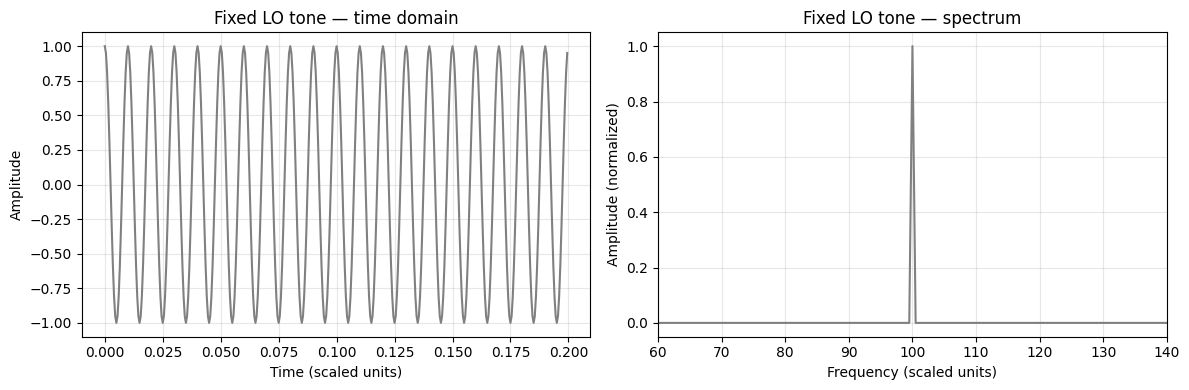

(<Figure size 1200x400 with 2 Axes>,
 array([<Axes: title={'center': 'Fixed LO tone — time domain'}, xlabel='Time (scaled units)', ylabel='Amplitude'>,
        <Axes: title={'center': 'Fixed LO tone — spectrum'}, xlabel='Frequency (scaled units)', ylabel='Amplitude (normalized)'>],
       dtype=object),
 array([0.000e+00, 5.000e-01, 1.000e+00, ..., 9.990e+02, 9.995e+02,
        1.000e+03], shape=(2001,)),
 array([8.53543403e-16, 1.30285399e-15, 7.42327362e-16, ...,
        6.65048245e-16, 1.00938695e-15, 1.16347431e-16], shape=(2001,)))

In [4]:
LO = np.cos(2 * np.pi * f_LO_A * t)
plot_time_and_spectrum(LO, t, fs, "Fixed LO tone", color=COLOR_LO, freq_xlim=(60, 140))


**This tone never changes.** The synthesizer just keeps outputting $\cos(2\pi f_\mathrm{LO} t)$ for
as long as the experiment runs; all of the frequency agility used to scan or dither across the NV
resonance comes entirely from the IQ modulator downstream (Sections 3–5), not from retuning this source.


## 3. Baseband I(t) and Q(t) Signals

For a target intermediate frequency $f_\mathrm{IF}$, the IQ modulator's two baseband drive channels are

$$I(t) = \cos(2\pi f_\mathrm{IF} t), \qquad Q(t) = \sin(2\pi f_\mathrm{IF} t).$$

These are in **quadrature** — 90° out of phase — which is exactly what makes single-sideband mixing
possible in Section 5.


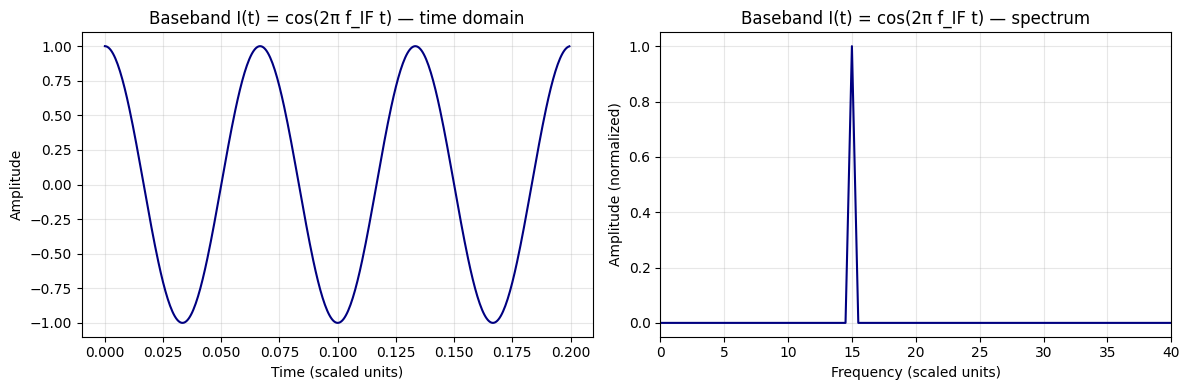

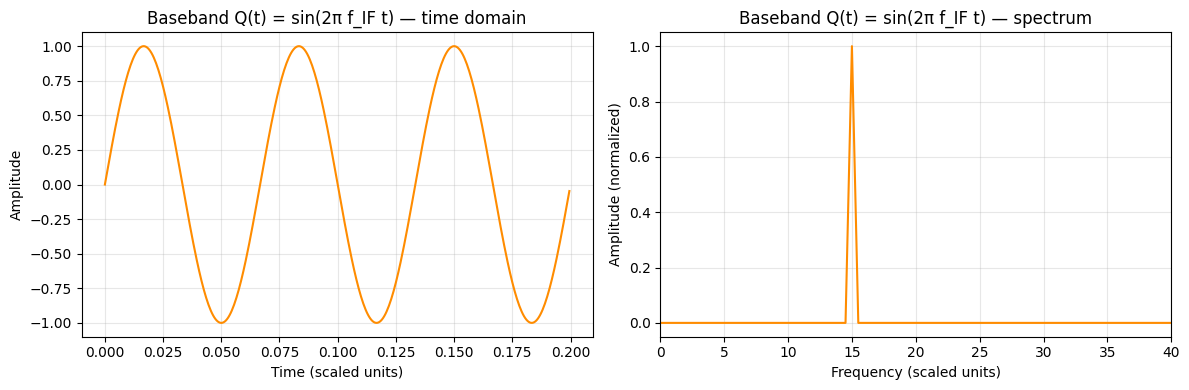

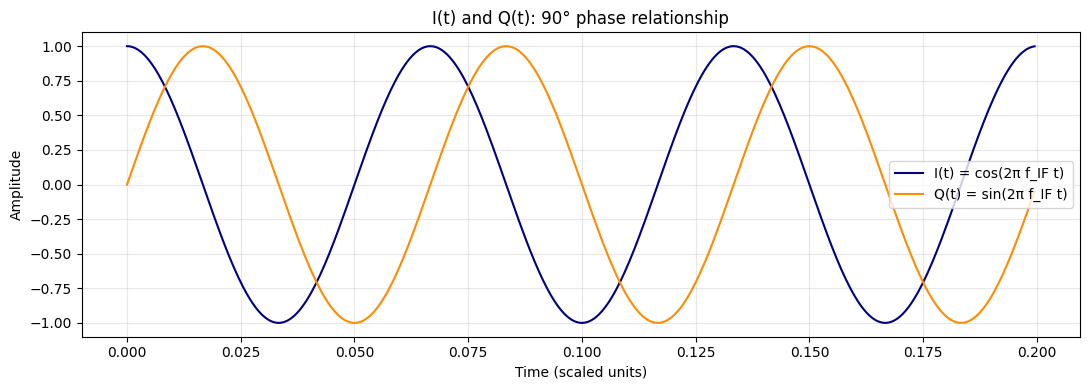

In [5]:
I_signal = np.cos(2 * np.pi * f_IF_demo * t)
Q_signal = np.sin(2 * np.pi * f_IF_demo * t)

plot_time_and_spectrum(I_signal, t, fs, "Baseband I(t) = cos(2\u03c0 f_IF t)", color=COLOR_I, freq_xlim=(0, 40))
plot_time_and_spectrum(Q_signal, t, fs, "Baseband Q(t) = sin(2\u03c0 f_IF t)", color=COLOR_Q, freq_xlim=(0, 40))

# Overlay to show the 90-degree phase relationship: I peaks exactly where Q crosses zero, and vice versa.
fig, ax = plt.subplots()
n_snip = int(0.2 * fs)
ax.plot(t[:n_snip], I_signal[:n_snip], color=COLOR_I, label="I(t) = cos(2\u03c0 f_IF t)")
ax.plot(t[:n_snip], Q_signal[:n_snip], color=COLOR_Q, label="Q(t) = sin(2\u03c0 f_IF t)")
ax.set_xlabel("Time (scaled units)")
ax.set_ylabel("Amplitude")
ax.set_title("I(t) and Q(t): 90\u00b0 phase relationship")
ax.legend()
plt.tight_layout()
plt.show()


## 4. Naive (Non-IQ) Mixing, for Comparison

Before showing IQ mixing, consider ordinary single-mixer multiplication using only the I channel:
$\mathrm{signal}(t) = \mathrm{LO}(t)\times I(t)$. By the product-to-sum identity,

$$\cos(2\pi f_\mathrm{LO}t)\cos(2\pi f_\mathrm{IF}t) = \tfrac12\cos\!\big(2\pi (f_\mathrm{LO}-f_\mathrm{IF})t\big)
+ \tfrac12\cos\!\big(2\pi (f_\mathrm{LO}+f_\mathrm{IF})t\big),$$

so the result contains **both** an upper ($f_\mathrm{LO}+f_\mathrm{IF}$) and a lower
($f_\mathrm{LO}-f_\mathrm{IF}$) sideband, each at half the amplitude of a single input tone.


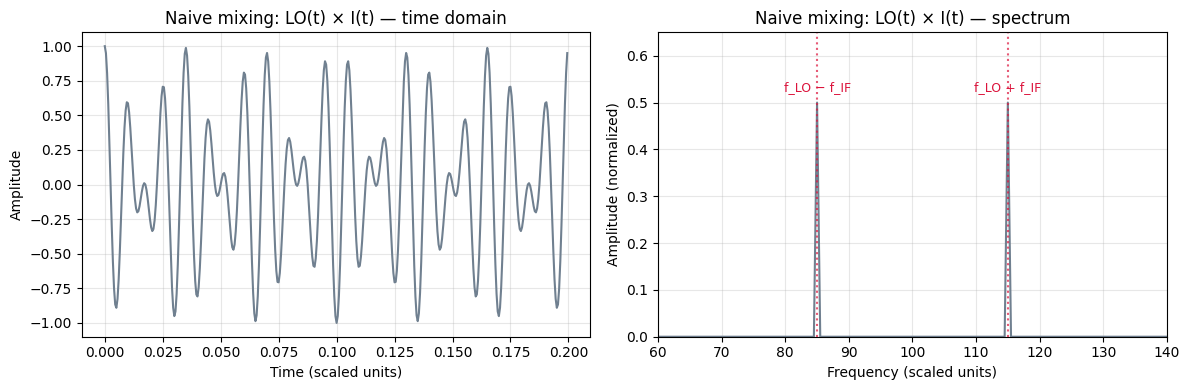

In [6]:
naive_mix = LO * I_signal
fig, axes, freqs_naive, spec_naive = plot_time_and_spectrum(
    naive_mix, t, fs, "Naive mixing: LO(t) \u00d7 I(t)", color=COLOR_NAIVE,
    freq_xlim=(60, 140), show=False)

ax_spec = axes[1]
lower_peak = f_LO_A - f_IF_demo
upper_peak = f_LO_A + f_IF_demo
peak_amp = spec_naive.max()
for pk, label in [(lower_peak, "f_LO \u2212 f_IF"), (upper_peak, "f_LO + f_IF")]:
    ax_spec.axvline(pk, color="crimson", linestyle=":", alpha=0.7)
    ax_spec.annotate(label, xy=(pk, peak_amp * 1.05), color="crimson", ha="center", fontsize=9)
ax_spec.set_ylim(0, peak_amp * 1.3)
plt.tight_layout()
plt.show()


**Both sidebands appear** because a single real-valued mixer product cannot distinguish "LO plus IF"
from "LO minus IF" — multiplying two real cosines is fundamentally symmetric in frequency. In most ODMR
drive-generation schemes only one of these two tones is wanted; the other is an unwanted **image
sideband** that would need to be filtered out afterward (wasting a filter stage, and impossible if the
wanted and image tones are too close together to filter apart). This is exactly the problem IQ mixing
solves without any filtering at all.


## 5. Full IQ Mixing (Single-Sideband Upconversion)

True IQ mixing combines *both* baseband channels against *both* quadratures of the LO:

$$V_\mathrm{out}(t) = I(t)\cos(2\pi f_\mathrm{LO}t) - Q(t)\sin(2\pi f_\mathrm{LO}t).$$

Substituting $I(t)=\cos(2\pi f_\mathrm{IF}t)$, $Q(t)=\sin(2\pi f_\mathrm{IF}t)$ and expanding with the
angle-addition formula collapses this to a **single** tone:

$$V_\mathrm{out}(t) = \cos(2\pi f_\mathrm{IF}t)\cos(2\pi f_\mathrm{LO}t) - \sin(2\pi f_\mathrm{IF}t)\sin(2\pi f_\mathrm{LO}t)
= \cos\!\big(2\pi (f_\mathrm{LO}+f_\mathrm{IF})t\big).$$

The $f_\mathrm{LO}-f_\mathrm{IF}$ image term cancels **exactly** (analytically) — it doesn't merely get
attenuated by a filter, it disappears from the algebra itself.


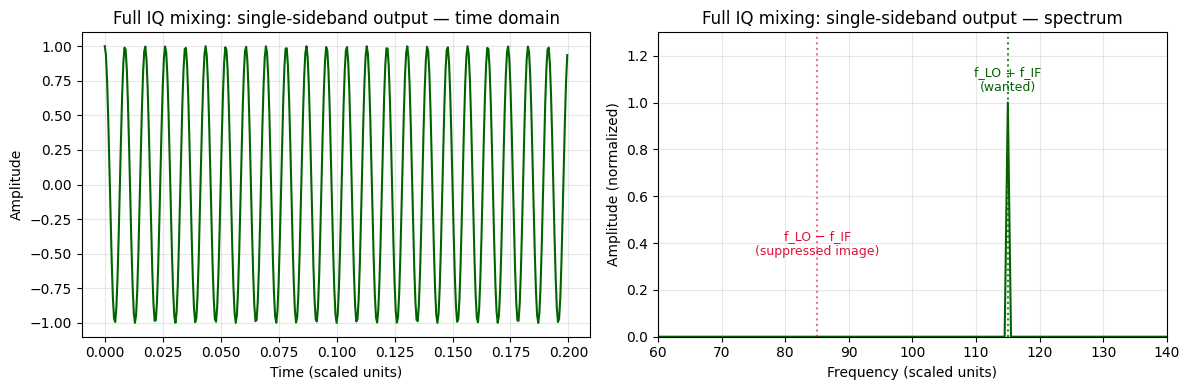

Image sideband suppression: > 240 dB (limited only by floating-point precision)
Wanted-tone amplitude: 1.000 (vs. 0.5 for either naive-mixing sideband above -- IQ mixing recovers the full amplitude in one sideband instead of splitting it in two)


In [7]:
V_out_demo = I_signal * np.cos(2 * np.pi * f_LO_A * t) - Q_signal * np.sin(2 * np.pi * f_LO_A * t)

fig, axes, freqs_iq, spec_iq = plot_time_and_spectrum(
    V_out_demo, t, fs, "Full IQ mixing: single-sideband output", color=COLOR_OUT,
    freq_xlim=(60, 140), show=False)

ax_spec = axes[1]
wanted = f_LO_A + f_IF_demo
image = f_LO_A - f_IF_demo
peak_amp = spec_iq.max()
ax_spec.axvline(wanted, color="darkgreen", linestyle=":", alpha=0.8)
ax_spec.annotate("f_LO + f_IF\n(wanted)", xy=(wanted, peak_amp * 1.05), color="darkgreen",
                  ha="center", fontsize=9)
ax_spec.axvline(image, color="crimson", linestyle=":", alpha=0.6)
ax_spec.annotate("f_LO \u2212 f_IF\n(suppressed image)", xy=(image, peak_amp * 0.35), color="crimson",
                  ha="center", fontsize=9)
ax_spec.set_ylim(0, peak_amp * 1.3)
plt.tight_layout()
plt.show()

# Quantify the image suppression directly from the FFT.
idx_wanted = np.argmin(np.abs(freqs_iq - wanted))
idx_image = np.argmin(np.abs(freqs_iq - image))
ratio = spec_iq[idx_image] / spec_iq[idx_wanted]
if ratio < 1e-12:
    print("Image sideband suppression: > 240 dB (limited only by floating-point precision)")
else:
    print(f"Image sideband suppression: {-20*np.log10(ratio):.1f} dB below the wanted tone")
print(f"Wanted-tone amplitude: {spec_iq[idx_wanted]:.3f} (vs. 0.5 for either naive-mixing sideband above "
      "-- IQ mixing recovers the full amplitude in one sideband instead of splitting it in two)")


**This cancellation is the entire reason for using two channels instead of one.** With a single
mixer (Section 4) the image sideband is unavoidable and must be filtered out after the fact. By splitting
the baseband drive into two quadrature channels ($I$ and $Q$) and combining them with the two LO
quadratures ($\cos$ and $-\sin$), the image term cancels algebraically at the point of mixing — no filter
required, and (as printed above) the wanted tone carries the *full* signal amplitude rather than half of
it. This is exactly the mechanism a two-channel IQ modulator (fed by an AWG or similar) uses to place the
NV drive frequency anywhere within the modulator's bandwidth of the fixed LO, simply by choosing
$f_\mathrm{IF}(t)$ — which is what the next two sections build on.


## 6. Scenario A: Centered LO, Symmetric Dither

Now we let $f_\mathrm{IF}$ become *time-varying* rather than a fixed tone. In this scenario the LO sits at
the nominal NV zero-field splitting, $f_\mathrm{LO,A}\approx$ 2.87 GHz-equivalent, and the IQ modulator
dithers sinusoidally by $\pm$70 MHz-equivalent around it — the classic lock-in-style approach for tracking
a single, already-approximately-known resonance:

$$f_\mathrm{IF}(t) = A_\mathrm{dither}\cos(2\pi f_m t).$$

Because $f_\mathrm{IF}(t)$ now varies in time, $I(t)=\cos(\phi_\mathrm{IF}(t))$ and $Q(t)=\sin(\phi_\mathrm{IF}(t))$
must use the *integrated* instantaneous phase $\phi_\mathrm{IF}(t) = 2\pi\int_0^t f_\mathrm{IF}(\tau)\,d\tau$
(via `integrate_phase`, Section 1) rather than a simple $2\pi f_\mathrm{IF}t$. This section uses a longer
time record than Sections 2–5 (same sample rate, more samples) purely to resolve the slow dither cycle
without smearing it in the spectrogram.


In [8]:
f_LO_scenA = f_LO_A
f_m_A = 0.03            # dither modulation rate (scaled units); slow compared to the RF carrier
duration_A = 100.0      # long enough for several full dither cycles AND a short-enough STFT window
t_A = np.arange(0, duration_A, 1.0 / fs)

f_IF_A_t = f_dither_amp * np.cos(2 * np.pi * f_m_A * t_A)
phase_IF_A = integrate_phase(f_IF_A_t, t_A)

I_A = np.cos(phase_IF_A)
Q_A = np.sin(phase_IF_A)
V_out_A = I_A * np.cos(2 * np.pi * f_LO_scenA * t_A) - Q_A * np.sin(2 * np.pi * f_LO_scenA * t_A)

# (b) instantaneous frequency: the simple analytic prediction, f_LO + f_IF(t) ...
inst_freq_A_analytic = f_LO_scenA + f_IF_A_t

# ... cross-checked numerically via the Hilbert transform of V_out(t) itself (trim edges: Hilbert
# transform has boundary artifacts at the very start/end of a finite record).
analytic_signal_A = scipy.signal.hilbert(V_out_A)
inst_phase_A = np.unwrap(np.angle(analytic_signal_A))
inst_freq_A_hilbert = np.diff(inst_phase_A) / (2 * np.pi) * fs
edge_A = max(1, int(0.01 * len(t_A)))


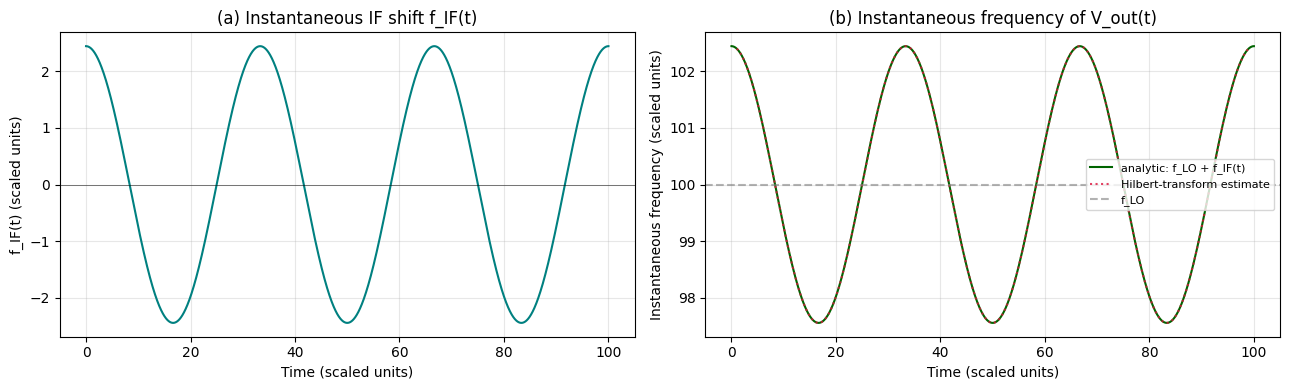

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(t_A, f_IF_A_t, color=COLOR_MOD)
axes[0].axhline(0, color="black", linewidth=0.7, alpha=0.5)
axes[0].set_xlabel("Time (scaled units)")
axes[0].set_ylabel("f_IF(t) (scaled units)")
axes[0].set_title("(a) Instantaneous IF shift f_IF(t)")

axes[1].plot(t_A, inst_freq_A_analytic, color=COLOR_OUT, label="analytic: f_LO + f_IF(t)")
axes[1].plot(t_A[edge_A:-edge_A], inst_freq_A_hilbert[edge_A - 1:-edge_A],
             color="crimson", linestyle=":", alpha=0.8, label="Hilbert-transform estimate")
axes[1].axhline(f_LO_scenA, color=COLOR_LO, linestyle="--", alpha=0.6, label="f_LO")
axes[1].set_xlabel("Time (scaled units)")
axes[1].set_ylabel("Instantaneous frequency (scaled units)")
axes[1].set_title("(b) Instantaneous frequency of V_out(t)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()


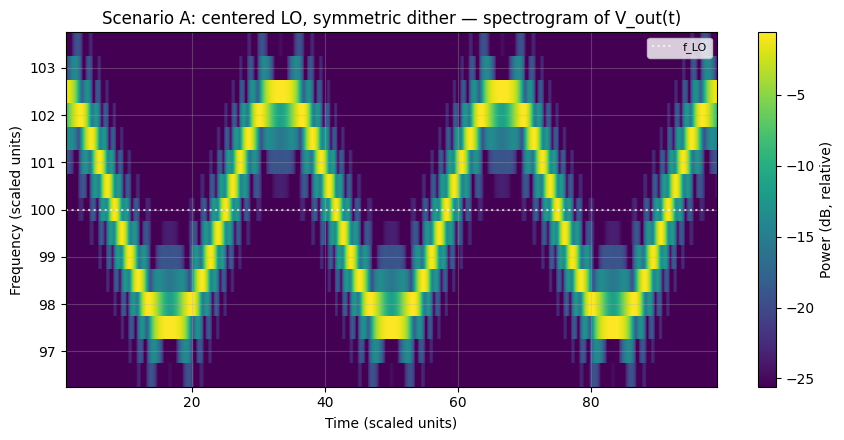

In [10]:
# (c) Spectrogram: nperseg/noverlap chosen to give frequency resolution fine enough to resolve the
# +-70 MHz-equivalent dither (~2.4 units) -- note the STFT window must ALSO stay short relative to
# the dither period (here, ~6% of it), otherwise the frequency changes appreciably within a single
# analysis window and the ramp/oscillation smears into a blurred wobble rather than a clean curve.
nperseg_A, noverlap_A = 4000, 3900
f_sp_A, t_sp_A, Sxx_A = scipy.signal.spectrogram(V_out_A, fs=fs, nperseg=nperseg_A, noverlap=noverlap_A)

band_A = (f_sp_A >= f_LO_scenA - 1.5 * f_dither_amp) & (f_sp_A <= f_LO_scenA + 1.5 * f_dither_amp)
Sxx_A_db = 10 * np.log10(Sxx_A[band_A] + 1e-16)

fig, ax = plt.subplots(figsize=(9, 4.5))
pcm = ax.pcolormesh(t_sp_A, f_sp_A[band_A], Sxx_A_db, shading="auto", cmap="viridis",
                     vmin=Sxx_A_db.max() - 25, vmax=Sxx_A_db.max())
ax.axhline(f_LO_scenA, color="white", linestyle=":", alpha=0.7, label="f_LO")
ax.set_xlabel("Time (scaled units)")
ax.set_ylabel("Frequency (scaled units)")
ax.set_title("Scenario A: centered LO, symmetric dither \u2014 spectrogram of V_out(t)")
ax.legend(loc="upper right", fontsize=8)
plt.colorbar(pcm, ax=ax, label="Power (dB, relative)")
plt.tight_layout()
plt.show()


The spectrogram shows the drive frequency **oscillating symmetrically above and below
$f_\mathrm{LO}$** — exactly the ±70 MHz-equivalent excursion set by `f_dither_amp` — repeating at the
dither rate $f_m$. This is the signature of Scenario A: a narrow band centered on one target resonance.


## 7. Scenario B: Offset LO, One-Directional Sweep

Here the LO is instead placed at the *low edge* of the NV search band, $f_\mathrm{LO,B}\approx$
2.80 GHz-equivalent, and $f_\mathrm{IF}(t)$ ramps linearly and repeatedly (a sawtooth) from 0 up to
140 MHz-equivalent — covering the *entire* search range in one direction, then resetting:

$$f_\mathrm{IF}(t) = \frac{A_\mathrm{sweep}}{2}\Big(1 + \mathrm{sawtooth}(2\pi f_\mathrm{rep}t)\Big) \in [0, A_\mathrm{sweep}].$$

`scipy.signal.sawtooth(..., width=1)` produces a rising-only ramp from $-1$ to $+1$ each period (a sharp
reset, no falling edge), which is rescaled here to run from $0$ to `f_sweep_span`.


In [11]:
f_LO_scenB = f_LO_B
f_rep_B = 0.03           # sweep repetition rate (scaled units); same as f_m_A for a fair, direct comparison
duration_B = 100.0
t_B = np.arange(0, duration_B, 1.0 / fs)

raw_saw = scipy.signal.sawtooth(2 * np.pi * f_rep_B * t_B, width=1)  # rising ramp, -1 .. +1
f_IF_B_t = f_sweep_span / 2.0 * (raw_saw + 1.0)                       # rescaled to 0 .. f_sweep_span

phase_IF_B = integrate_phase(f_IF_B_t, t_B)
I_B = np.cos(phase_IF_B)
Q_B = np.sin(phase_IF_B)
V_out_B = I_B * np.cos(2 * np.pi * f_LO_scenB * t_B) - Q_B * np.sin(2 * np.pi * f_LO_scenB * t_B)

inst_freq_B_analytic = f_LO_scenB + f_IF_B_t

analytic_signal_B = scipy.signal.hilbert(V_out_B)
inst_phase_B = np.unwrap(np.angle(analytic_signal_B))
inst_freq_B_hilbert = np.diff(inst_phase_B) / (2 * np.pi) * fs
edge_B = max(1, int(0.01 * len(t_B)))


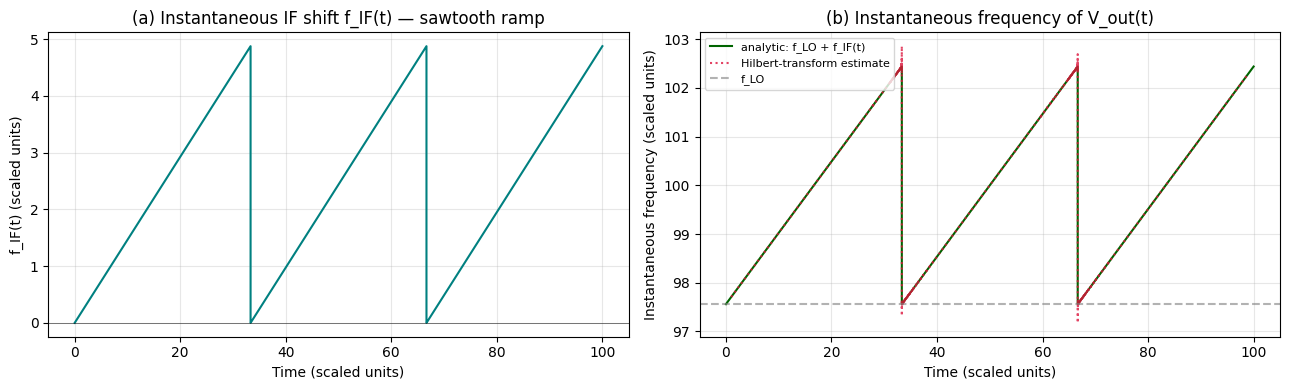

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(t_B, f_IF_B_t, color=COLOR_MOD)
axes[0].axhline(0, color="black", linewidth=0.7, alpha=0.5)
axes[0].set_xlabel("Time (scaled units)")
axes[0].set_ylabel("f_IF(t) (scaled units)")
axes[0].set_title("(a) Instantaneous IF shift f_IF(t) \u2014 sawtooth ramp")

axes[1].plot(t_B, inst_freq_B_analytic, color=COLOR_OUT, label="analytic: f_LO + f_IF(t)")
axes[1].plot(t_B[edge_B:-edge_B], inst_freq_B_hilbert[edge_B - 1:-edge_B],
             color="crimson", linestyle=":", alpha=0.8, label="Hilbert-transform estimate")
axes[1].axhline(f_LO_scenB, color=COLOR_LO, linestyle="--", alpha=0.6, label="f_LO")
axes[1].set_xlabel("Time (scaled units)")
axes[1].set_ylabel("Instantaneous frequency (scaled units)")
axes[1].set_title("(b) Instantaneous frequency of V_out(t)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()


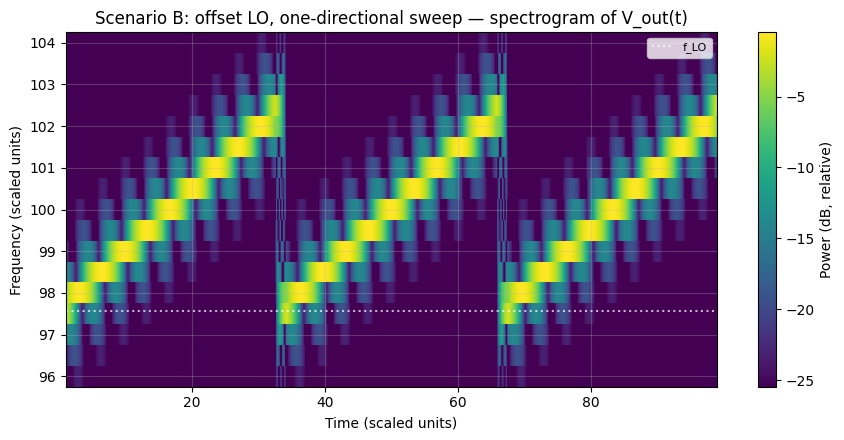

In [13]:
# Same window-vs-period reasoning as Scenario A: the window must stay short relative to the sweep
# period, or the sawtooth ramp smears into a blurred wobble instead of a clean rising line.
nperseg_B, noverlap_B = 4000, 3900
f_sp_B, t_sp_B, Sxx_B = scipy.signal.spectrogram(V_out_B, fs=fs, nperseg=nperseg_B, noverlap=noverlap_B)

band_B = (f_sp_B >= f_LO_scenB - 2.0) & (f_sp_B <= f_LO_scenB + f_sweep_span + 2.0)
Sxx_B_db = 10 * np.log10(Sxx_B[band_B] + 1e-16)

fig, ax = plt.subplots(figsize=(9, 4.5))
pcm = ax.pcolormesh(t_sp_B, f_sp_B[band_B], Sxx_B_db, shading="auto", cmap="viridis",
                     vmin=Sxx_B_db.max() - 25, vmax=Sxx_B_db.max())
ax.axhline(f_LO_scenB, color="white", linestyle=":", alpha=0.7, label="f_LO")
ax.set_xlabel("Time (scaled units)")
ax.set_ylabel("Frequency (scaled units)")
ax.set_title("Scenario B: offset LO, one-directional sweep \u2014 spectrogram of V_out(t)")
ax.legend(loc="upper right", fontsize=8)
plt.colorbar(pcm, ax=ax, label="Power (dB, relative)")
plt.tight_layout()
plt.show()


The spectrogram shows a **repeated, one-directional ramp**: the drive frequency climbs steadily
from $f_\mathrm{LO}$ up to $f_\mathrm{LO}+140$ MHz-equivalent, then snaps back down and repeats — it never
goes *below* $f_\mathrm{LO}$. This is the signature of Scenario B: covering the full search range from one
edge to the other in a single pass, repeated at the sweep rate.


## 8. Side-by-Side Comparison Summary

Both spectrograms are plotted next to each other on a **shared frequency axis** (same limits, same color
scale convention), with the true NV resonance search range (2.80–2.94 GHz-equivalent) shaded, so the
difference in *coverage* is immediately visually obvious.


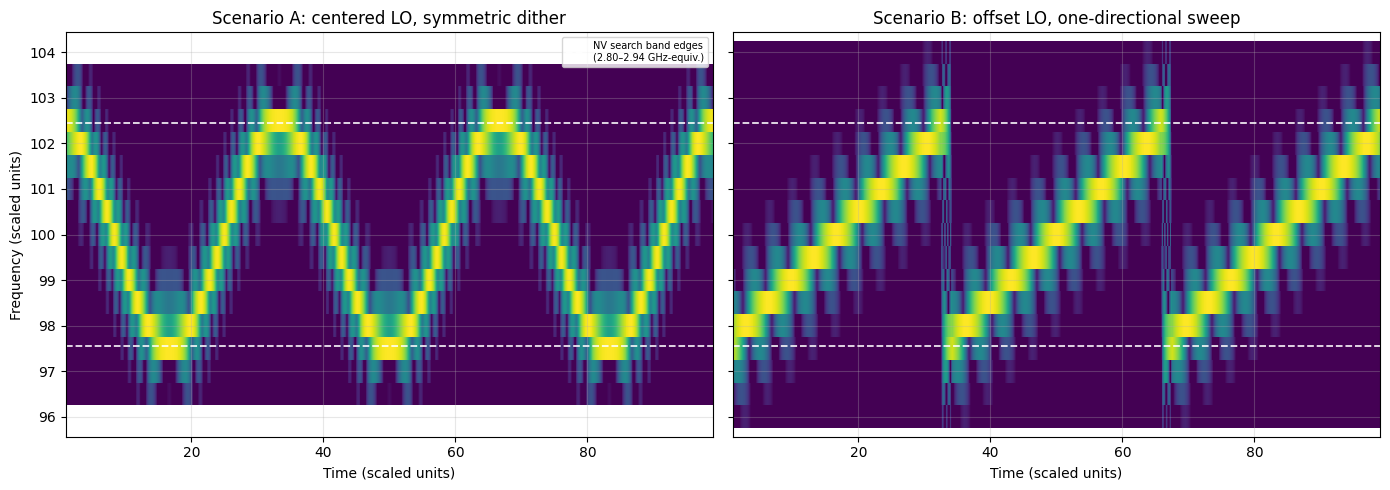

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

pcm0 = axes[0].pcolormesh(t_sp_A, f_sp_A[band_A], Sxx_A_db, shading="auto", cmap="viridis",
                           vmin=Sxx_A_db.max() - 25, vmax=Sxx_A_db.max())
axes[0].set_title("Scenario A: centered LO, symmetric dither")
axes[0].set_xlabel("Time (scaled units)")
axes[0].set_ylabel("Frequency (scaled units)")

pcm1 = axes[1].pcolormesh(t_sp_B, f_sp_B[band_B], Sxx_B_db, shading="auto", cmap="viridis",
                           vmin=Sxx_B_db.max() - 25, vmax=Sxx_B_db.max())
axes[1].set_title("Scenario B: offset LO, one-directional sweep")
axes[1].set_xlabel("Time (scaled units)")

y_lo = min(f_LO_scenA - 1.5 * f_dither_amp, f_LO_scenB - 2.0)
y_hi = max(f_LO_scenA + 1.5 * f_dither_amp, f_LO_scenB + f_sweep_span + 2.0)
for ax in axes:
    ax.axhline(nv_band_low, color="white", linestyle="--", linewidth=1.3, alpha=0.9,
               label="NV search band edges\n(2.80\u20132.94 GHz-equiv.)")
    ax.axhline(nv_band_high, color="white", linestyle="--", linewidth=1.3, alpha=0.9)
    ax.set_ylim(y_lo, y_hi)
axes[0].legend(loc="upper right", fontsize=7)

plt.tight_layout()
plt.show()


**Summary.** Scenario A (centered LO, symmetric dither) only ever visits a narrow band around one
known resonance — it is well suited to **narrowband tracking/dithering around a single, already-located
resonance** (e.g. lock-in-style feedback once a resonance has been found), but it never reaches the edges
of the full NV search band on its own. Scenario B (offset LO, one-directional sweep), in contrast,
deliberately spans the *entire* search range from one edge to the other in a single repeated pass — it is
well suited to a **fast, full-band sweep** when the resonance location is not yet known (or may have
drifted outside a narrow dither range), consistent with the fast full-band sweep techniques discussed
earlier. In practice, an ODMR system might use Scenario B's wide sweep to first locate a resonance, then
switch to Scenario A's narrow dither to track it with better update rate and SNR once found.
